# 2. 临界阈值：0.72 还是 0.733？

原文说"经大量实验验证约 0.72"，没给判据、没给步长、没给仿真时长。
这三项任一变化都会让"阈值"漂移，所以先把口径钉住：

- 判据：每个驱动周期在**精确的 $\tau=2\pi k$ 时刻**插值取 $x$，取稳态后半段标准差 $p_{std}$；
- 周期态判据 $p_{std}<0.02$；
- 步长 $h=2\pi/300$（**整除** $2\pi$），仿真 600 s、丢弃前 300 s。

## 为什么必须"精确 2π 时刻"

这是本次复现最重要的一处方法学修正。若按"每 $N$ 步采一次"（$N=\mathrm{round}(2\pi/h)$），
$h$ 不整除 $2\pi$ 时采样相位每周期漂一点点，累积起来让 Poincaré 点沿着轨道游走，
$p_{std}$ 凭空多出 0.1 量级。实测对照：

| 采样方式 | $\lambda=0.734$ 的 $p_{std}$ | 判读 |
|---|---|---|
| 每 314 步采一次（$h=0.02$，$2\pi/h=314.159$） | 0.103 | ❌ 误判为混沌 |
| 精确 $2\pi k$ 时刻插值 | **0.000000** | ✅ 收敛到一点 |

也就是说，**阈值 0.736 与 0.733 的差别，一半来自判据伪迹**。


In [1]:

import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import s2sim as S

DATA = pathlib.Path("_data")
OUT = pathlib.Path("../复现输出/s2-figs"); OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.grid": True, "grid.alpha": .25,
})
FIGS = []
def savefig(name):
    p = OUT / name
    plt.savefig(p, bbox_inches="tight", facecolor="white")
    FIGS.append(str(p)); plt.show(); print("图已保存:", p)

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


临界带 [0.732, 0.734]  ->  lambda_c ≈ 0.7330   （原文 0.72）


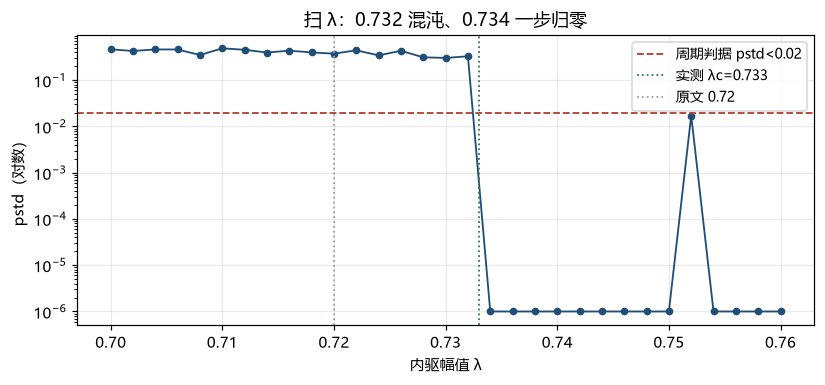

图已保存: ..\复现输出\s2-figs\s2-02-临界阈值.png
注意 0.734 之后 pstd 直接落到 1e-6 以下 —— 精确采样下周期态是真正的『一点』。


In [2]:

d = load("sweep")
lam = np.array(d["lam"]); p = np.array(d["pstd"])
print(f"临界带 {d['jump']}  ->  lambda_c ≈ {d['lam_c']:.4f}   （原文 {d['paper']}）")
fig, ax = plt.subplots(figsize=(7.6, 3.6))
ax.semilogy(lam, np.maximum(p, 1e-6), "o-", ms=4, color="#1f4e79", lw=1.2)
ax.axhline(0.02, color="#b3402f", ls="--", lw=1.2, label="周期判据 pstd<0.02")
ax.axvline(d["lam_c"], color="#2e7d4f", ls=":", lw=1.2, label=f"实测 λc={d['lam_c']:.3f}")
ax.axvline(d["paper"], color="#9aa3ad", ls=":", lw=1.2, label="原文 0.72")
ax.set_xlabel("内驱幅值 λ"); ax.set_ylabel("pstd（对数）")
ax.set_title("扫 λ：0.732 混沌、0.734 一步归零")
ax.legend(fontsize=9)
plt.tight_layout(); savefig("s2-02-临界阈值.png")
print("注意 0.734 之后 pstd 直接落到 1e-6 以下 —— 精确采样下周期态是真正的『一点』。")


## 读法

- 相变是**突变**，不是渐变：$0.732\to0.734$ 之间 $p_{std}$ 从 0.33 直接归零。
- 论文的 0.72 与实测 0.733 差 0.013（约 1.8%）。差异来源不是"论文错了"，
  而是 $k$、判据、噪声、求解器四者共同决定临界值，原文未交代其中任何一项。
  **引用 0.72 时必须连条件一起给。**
- 另有一个副作用值得记住：$p_{std}$ 在周期态精确为 0，意味着判据本身**没有"软"过渡区**，
  噪声一旦把点推开就会立刻破零。第 5 章会看到，这正是 $-23$ dB 判决很"脆"的原因。
